# Micro-mineral analysis: Simplified workflow used within MScRes project 

This workflow contains a simplified example of the workflow used within my Masters by Research project by which I investigated enriched rims within the sulphide minerals of the Rum layered intrusion, Scotland.

Workflow was adapted from previous works within the University of Glasgow mineral analysis group, inlcuding Faisal Khudhur, Matt Divers, Dr Joshua Franz Einsle, and Francesco Perrone.
https://doi.org/10.1002/adsu.202300559

The link to my thesis, which contains more indepth results, including more sites and subsquent cluster minerology will be below. Futher analysis within my thesis includes how ML results differ under different collection parameters, which is currently being adapted for publication. 

Thesis DOI: https://doi.org/10.5525/gla.thesis.85876


---

## 1. Import libaries 

In [1]:
import hyperspy.api as hs # hyperspectal analysis library - calls on a lot of the packages listed below
import numpy as np # array mathematics/indexing
# visualisation ported from matlab
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import colors
from matplotlib.colors import to_rgb, LinearSegmentedColormap, ListedColormap
from matplotlib import cm
import matplotlib.patches as patches
from matplotlib.lines import Line2D
%matplotlib inline
# machine learning outside the hyperspy ecopsystem
import sklearn as skl
from sklearn import preprocessing
from sklearn.decomposition import PCA, NMF, FactorAnalysis, FastICA # different types of linear decomposition
import pandas as pd
import hdbscan # used for cluster analysis 
import os
import h5py

---

## 2. Custom functions 

### 1. Poisson Noise Scaling

Altered from Keenan (2004) by Matt Divers et al., (2024) of Univeristy of Glasgow and University of Manchester. 

What this function does: Unfolds the navigation and signal dimensions to allow the data to be processed as a 2D matrix. Keenan-Kotula scaling then computes the rows and collumns sums, takes the square root of each of these values, and scales the intensity of the values to stablise the varience within the data set. 

Why this function is used: This function is used for 'cleaning up' the data before decomposition and clustering. Poisson_noise_norm actively reduces noise and amplifies smaller features which were originally lost within the large data set. It achieves this by giving these features a larger weight per pixel value, which in turn helps them be retained during later decomposition.

In [2]:
def poisson_noise_norm(signal):
    """Normalises a HyperSpy-style signal for Poissonian noise based on [Keenan2004]_.
    
    Parameters
    ----------
    signal : HyperSpy Signal
        A HyperSpy data stack (e.g., EDS spectrum image).
        
    Returns
    -------
    s_norm : HyperSpy Signal
        The normalized signal object.
    d_norm : numpy.ndarray
        The normalized data in (y, x, energy_channels) format.
    dc : numpy.ndarray
        The vectorized/unfolded normalized data in ((y*x), energy_channels) format.
    """
    # Retrieve original data shape
    y, x, e = signal.data.shape
    
    print(f"Initial mean={signal.data.mean()}, initial max={signal.data.max()}, initial min={signal.data.min()}")
    
    with signal.unfolded():
        # Check axes manager and copy data accordingly
        if signal.axes_manager[0].index_in_array == 0:
            dc = signal.data.copy()
        else:
            dc = signal.data.T.copy()

        # Ensure correct data type for scaling
        dc = dc.astype('float64')
        
        # Calculate sums along axes
        aG = dc.sum(axis=1).squeeze()
        bH = dc.sum(axis=0).squeeze()
        
        root_aG = np.sqrt(aG)[:, np.newaxis]
        root_bH = np.sqrt(bH)[np.newaxis, :]

        # Ignore numpy warnings for division by zero, setting 0/0 = 0 via nan_to_num
        with np.errstate(divide="ignore", invalid="ignore"):
            # Equation 8 of Keenan & Kotula (2004)
            dc /= root_aG * root_bH
            dc = np.nan_to_num(dc)
          
    print(f"Scaled shape: {dc.shape}")
    print(f"Scaled mean={dc.mean()}, scaled max={dc.max()}, scaled min={dc.min()}")
          
    # Convert unfolded array back to original spatial dimensions
    d_norm = dc.reshape(y, x, e)
          
    # Convert numpy array back into a HyperSpy signal object
    s_norm = hs.signals.EDSSEMSpectrum(d_norm)
    s_norm.metadata = signal.metadata
    s_norm.axes_manager = signal.axes_manager

    return s_norm, d_norm, dc

---

## 3. Pre-processing 

This section of the workflow involves loading in the EDS-SEM data that is wished to be analysed and defining relevent terms.

In [3]:
eds = hs.load('2024 - chromite count rate tests/calibrated/site01-02_calibrated.hspy')

Defining relevent terms: Here we are using axes_manager, a hyperpsy tool, to manage the dimensions of the data set.

Python uses 0 based indexing, so [2] is actually equivilent to the third axis.

.scale refers to the dispersion in Kev in each channels along the axis

.offset refers to the starting energy value on the axis.

The navagatior scale has been set to the first axis.

In [4]:
scale = eds.axes_manager[2].scale
offset = eds.axes_manager[2].offset
nav_scale = eds.axes_manager[0].scale

Here we are taking hyperspys build in element data base, and using .as_dictionary, converting it to work outside hyperspys constraints.
The second line recieves the elements that have been defined for the data set.

In [5]:
ele_dic = hs.material.elements.as_dictionary()
elements = eds.metadata.Sample.elements
print(elements)

['Al', 'C', 'Ca', 'Cr', 'Cu', 'Fe', 'Mg', 'Na', 'Ni', 'O', 'S', 'Si', 'Ti']


Next we plot the EDS data by combining the first and second axis of the data. 0 & 1 representing the X & Y of the spectral image map. Xray lines are plotted to identify elements present in the sample.

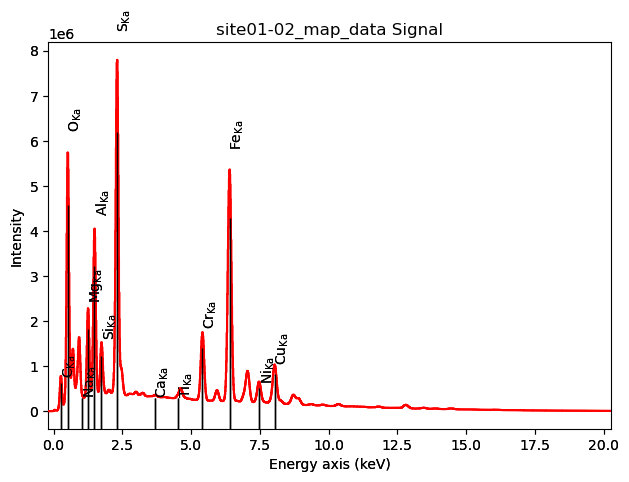

In [6]:
eds.sum(axis=(0,1)).plot(xray_lines=True) 

Retrieving the eds data shape. 

.data works with a numpy array of the data provided

In [7]:
y, x, e = eds.data.shape 
print(f'X = {x}, Y = {y}, Energy channels = {e}') 

X = 681, Y = 691, Energy channels = 2048


Lastly we do a simple plot to see an overview image of the data 

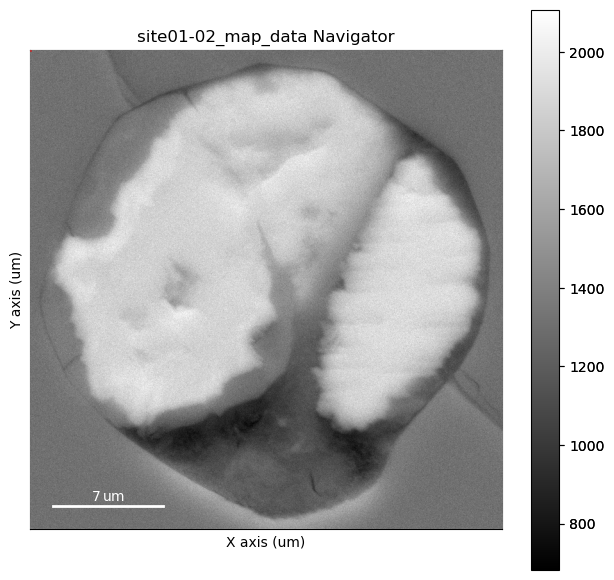

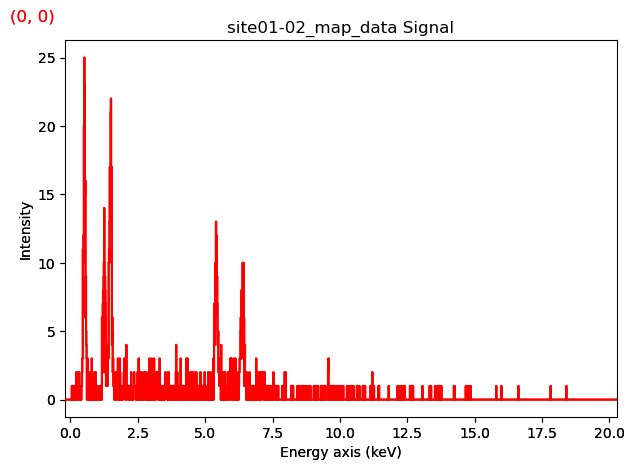

In [8]:
eds.plot() 

---

## 4. Poisson Noise Scaling 

Defined in the custom function section, poisson_noise_norm has three outputs:

Scaled map data as a Hyperspy object, Scaled map data as a numpy array, and a scaled vector also produced as a numpy array.



In [9]:
eds_norm, d_norm, d_vect = poisson_noise_norm(eds)

Initial mean=0.7375935756440049, initial max=79, initial min=0
Scaled shape: (470571, 2048)
Scaled mean=2.4143864456317326e-05, scaled max=0.02643505285727147, scaled min=0.0


C:\Users\2455292P\AppData\Local\anaconda3\envs\hyperspy174\lib\site-packages\hyperspy\signal.py:2451: UserWarning: Setting the `metadata` attribute is deprecated and will be removed in HyperSpy 2.0. Use the `set_item` and `add_dictionary` methods of the `metadata` attribute instead.
  warnings.warn(


After these outputs are generated, you can then plot the scaled data.

eds_norm.plot plots an interactive interface with a navigator (an overview image) and a spectrum viewer (only if you plot outwith the notebook!!).

eds_norm.sum plots the 2D spectra of the total area summed. 

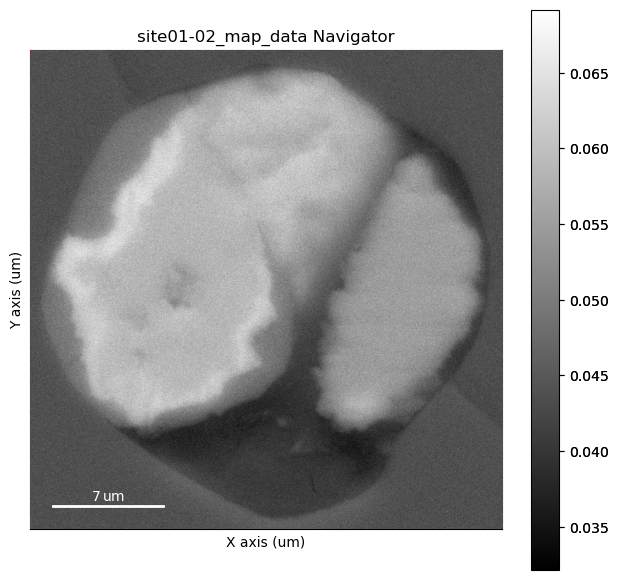

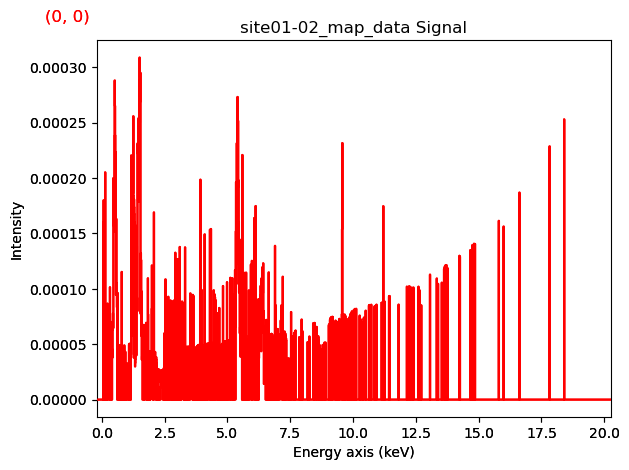

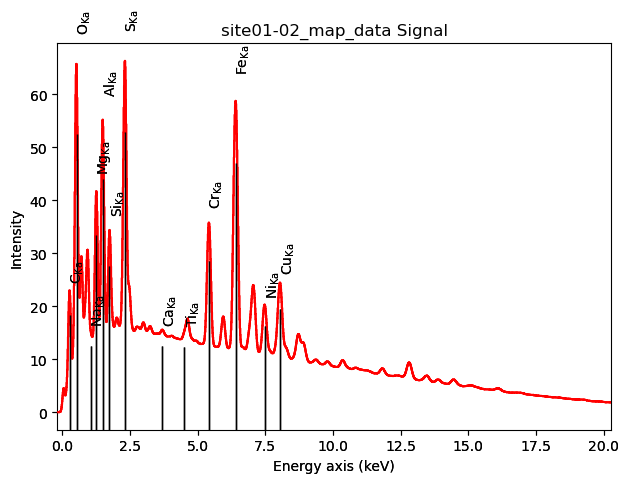

In [10]:
eds_norm.plot()
eds_norm.sum(axis=(0,1)).plot(xray_lines=True)

Compare the above image and spectrum plots with those prior in the pre-processing stage. The noise is significantly reduced, and importantly, the enriched rim is more amplified post poisson noise scaling. This will ensure that smaller features are fairly represented and not overpowered during data decomposition such as PCA/FA.

Save the Poisson scaled data as a numpy array

In [12]:
#np.save('preprocessing/EDSdata_PoissonScaled_site01-02.npy', d_vect)

---

## 5. Defining the optimum number of Factors using Factor Analysis 

The first pass of FA is ran with a overestimated number of factors such as 100, 20 or 10, use whichever the data pack and time contraints allow. The optimum number of factors can then be inferred from produced skree plot and heat maps.

For the sake of this being a simplified workflow, a small number of only 10 factors are being used for this step.

In [13]:
n_fact = 10 #define number of components/factors
fa = FactorAnalysis(n_components = n_fact, rotation='varimax', random_state=0) #orthangonal rotation, random seed state
fa.fit(d_vect) #fitting the model to the previous PNS vector which is saved as a numpy array

FactorAnalysis(n_components=10, rotation='varimax')

Within this project a varimax rotation was used whilst performing FA. After a factor is determined, a rotation occurs within the data's dimensional space to determine the following factors. Varimax rotation is an orthangonal rotation, used when the factors are unrelated. Varimax searchs the loadings produced to find a rotation that maximises the varience of the loadings within a factor.

A more detailed discription of FA and varimax rotation can be found on pages 54 and 55 of my thesis.

**

Check the model has fit correctly and store the score and loads, and reshape the score into images.

In [14]:
# preserve score matrices as variable score
score = fa.transform(d_vect)
print(score.shape)
# reshape the score matrix into images
score_ims = score.reshape((y, x, n_fact))
print(score_ims.shape)
# preserve loadings matrices as variable loads
loads = fa.components_
print(loads.shape)

(470571, 10)
(691, 681, 10)
(10, 2048)


Since the SEM-EDS data sets are often very large, running a PCA scree plot is not always feasible.

Factor importance plots can be plotted by using estimates from the loadings.

[6.08663956e-07 1.80902214e-07 1.29989688e-07 4.67228308e-08
 4.98483161e-08 3.75492666e-09 3.34587592e-09 9.83380374e-10
 4.20297413e-10 1.47552777e-10]


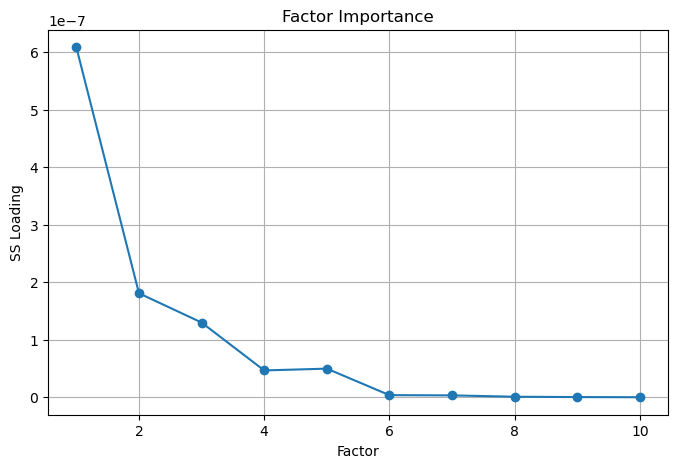

In [15]:
loads = fa.components_ #factor loadings contain the relationship between rows (factors) and columns (variables) and are stored in fa.components

ss_loadings = np.sum(loads**2, axis=1) #sum of squared loadings per factor
print(ss_loadings) #prints the results of the summed squared loadings per factors, indicating each factors strength, higher value = more relevent factor

plt.figure(figsize=(8,5))
plt.plot(
    range(1, len(ss_loadings)+1),
    ss_loadings,
    marker='o'
)
#range(1, len(ss_loadings)+1) is equal to the x-axis
#ss_loadings become th y-axis
#marker='o' is simply a marker making each point easier to see

plt.xlabel('Factor') #x-axis
plt.ylabel('SS Loading') #y-axis
plt.title('Factor Importance') #title
plt.grid(True) #plots grid lines
plt.show() #plots the figure

This graph highlights that the majority of the data structure is explained between 1-4, the optimal number of factors, in which the most variance within the data set can be explained, is 6, and factors past 6 contribute very little.

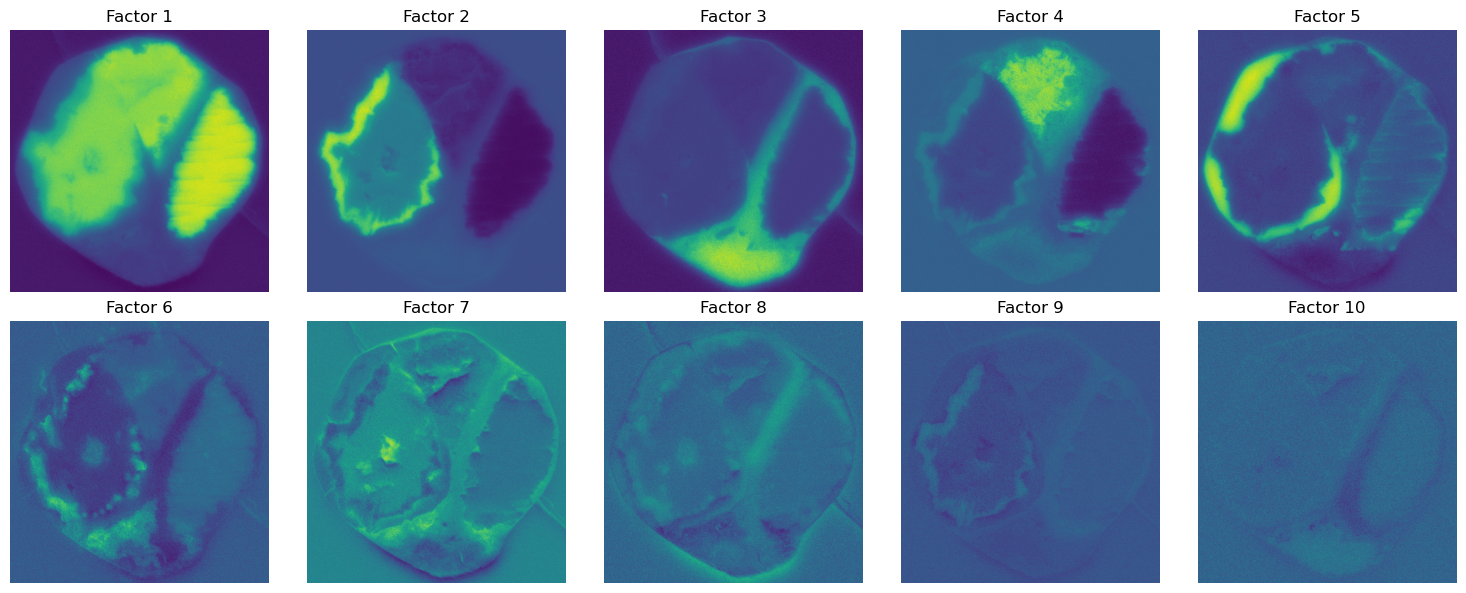

In [16]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6)) #creates figure and defines the structure 

for i, ax in enumerate(axes.flat):
    im = ax.imshow(score_ims[:, :, i], cmap='viridis')
    ax.set_title(f'Factor {i+1}')
    ax.axis('off')
#this loop allows the heat maps of each factor to be plotted
#for i, ax in enumerate(axes.flat): 
#axes.flat is a function that simplifies subplot iteration by converting a 2D axes array into a 1D iterator. It applies the same action to all subplots.
#enumerate is a function for loops, turns into a object
#im = ax.imshow(score_ims.....) turns the numerical numbers into colours 
#score_ims [] plots all rows (:), columns (:), factors(i) 
#im stores the image as an object
#python starts counting from 0 hense i+1
#ax.axis off removes tick marks

plt.tight_layout() #funtion that adjusts space between plots/titles
plt.show()

Heat maps support previous scree importance plot. Factors past 6 are noisy and contribute very little, some picking up more surface/textural conditions irrelvent to mineral microanalysis.

Factor 2 is seen to pick out the enriched rim!

Overall, 6 factors seem to be optimal and relevent. 

A final FA pass using the optimal 6 factors can now be performed to prepare for clustering.

---

## 6. FA with th optimal number of factors

In [17]:
n_fact = 6
fa = FactorAnalysis(n_components = n_fact, rotation='varimax', random_state=0) # varimax rotation used
fa.fit(d_vect)

FactorAnalysis(n_components=6, rotation='varimax')

In [18]:
# preserve score matrices as variable score
score = fa.transform(d_vect)
print(score.shape)
# reshape the score matrix into images
score_ims = score.reshape((y, x, n_fact))
print(score_ims.shape)
# preserve loadings matrices as variable loads
loads = fa.components_
print(loads.shape)

(470571, 6)
(691, 681, 6)
(6, 2048)


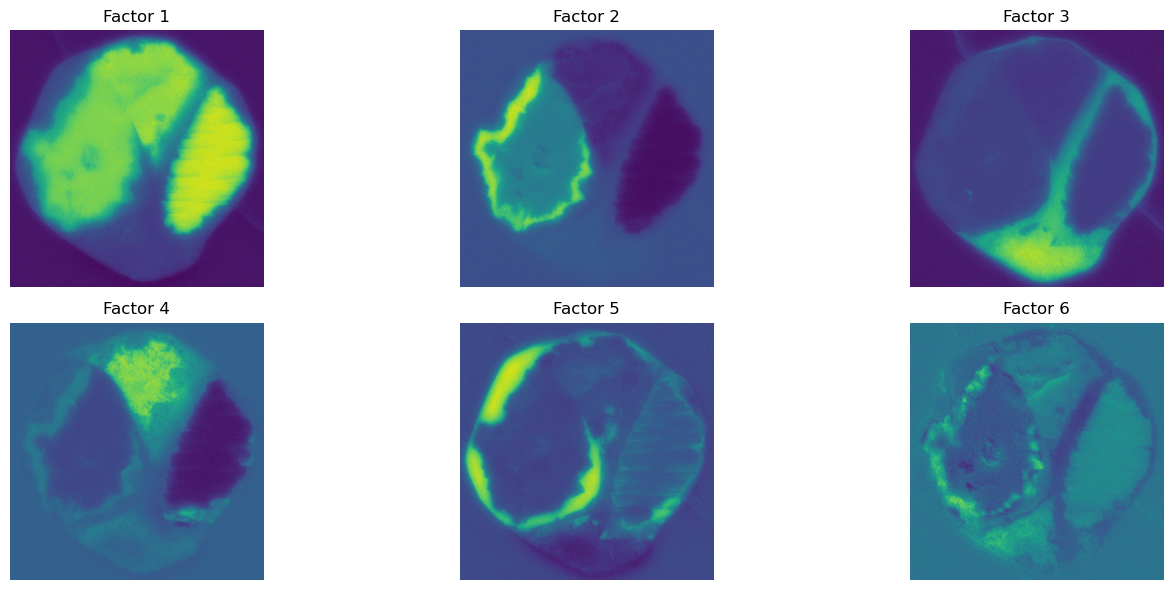

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(15, 6)) #creates figure and defines the structure 

for i, ax in enumerate(axes.flat):
    im = ax.imshow(score_ims[:, :, i], cmap='viridis')
    ax.set_title(f'Factor {i+1}')
    ax.axis('off')
#this loop allows the heat maps of each factor to be plotted
#for i, ax in enumerate(axes.flat): 
#axes.flat is a function that simplifies subplot iteration by converting a 2D axes array into a 1D iterator. It applies the same action to all subplots.
#enumerate is a function for loops, turns into a object
#im = ax.imshow(score_ims.....) turns the numerical numbers into colours 
#score_ims [] plots all rows (:), columns (:), factors(i) 
#im stores the image as an object
#python starts counting from 0 hense i+1
#ax.axis off removes tick marks

plt.tight_layout() #funtion that adjusts space between plots/titles
plt.show()

---

## 7. HDBSCAN (clustering)

Heirarchical Density-Based Spatial Clustering Applications with Noise (HDBSCAN) is the clustering algorithm of choice for this project.

In [20]:
clust = hdbscan.HDBSCAN(min_cluster_size=100, min_samples=None, prediction_data=True) 
clust.fit(score) #fits the data to the score, previously defined as 'score = fa.transform(d_vect)', which is equal to (470571, 6). after fitting the findings are then stored inside 'clust'.
labels = clust.labels_ #computs the hard cluster labels
print(labels.shape) 
n_clusters = len(np.unique(labels)) #finds unique label values to produce total number of clusters including noise (outliers)
print(f'Number of clusters: {str(n_clusters)}')
labels[labels==-1] = n_clusters-1 # n_cluster-1 since labels start at 0


(470571,)
Number of clusters: 12


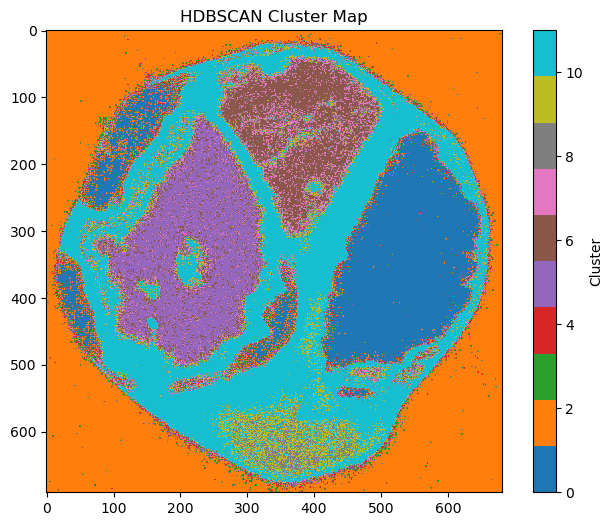

In [36]:
cluster_map = labels.reshape(y, x) #shapes data so that the 1D label array becomes a 2D array, which can then be shown as an image.

plt.figure(figsize=(8,6))
plt.imshow(cluster_map, cmap='tab10') #plot image show, converting numbers in 'cluster_map' into colours, using tab10 colours, producing a clustered image.
plt.colorbar(label='Cluster') 
plt.title('HDBSCAN Cluster Map')
plt.show()

As you can see, the enriched rim investigated in my MScRes project is picked out within clustering.

In [42]:
labels_hspy = hs.signals.Signal2D(label_map) # turn the labelled image into a Signal2D object

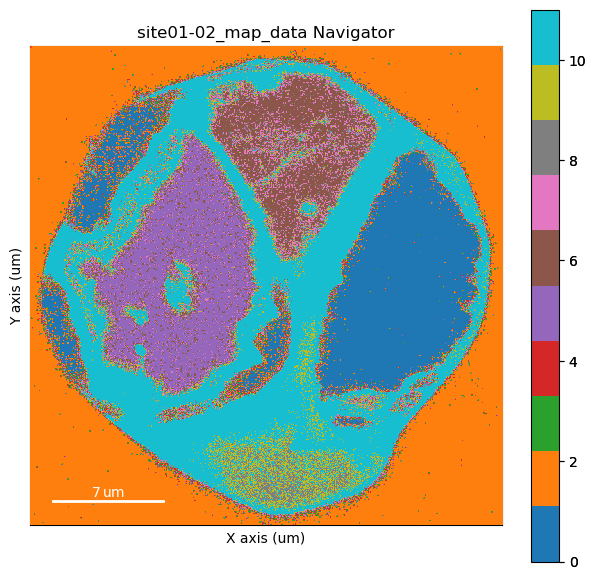

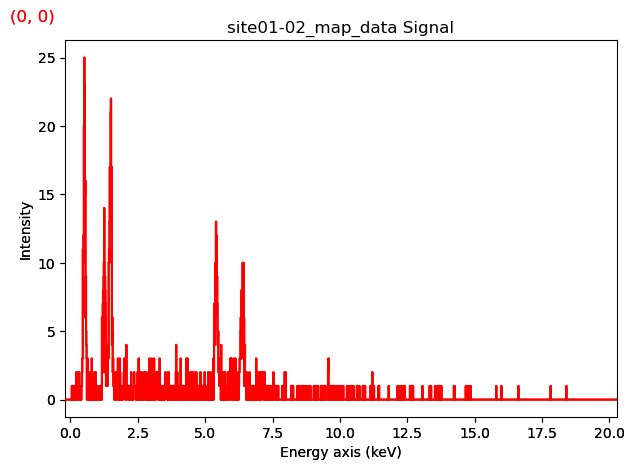

In [43]:
eds.plot(navigator=labels_hspy, xray_lines=False, 
         navigator_kwds=dict(colorbar=True,
                             cmap='tab10',
                             axes_ticks=False)) 
# plot out with the notebook to navigate 

Next we can produce lone cluster maps as a binary mask, its best to do this in black and white to really see what each cluster is pulling out.

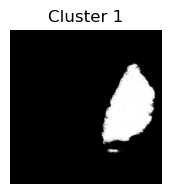

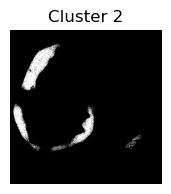

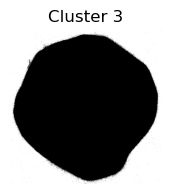

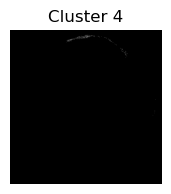

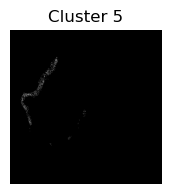

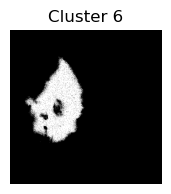

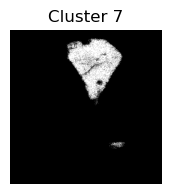

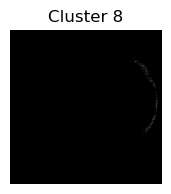

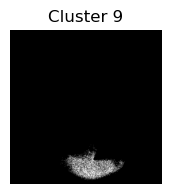

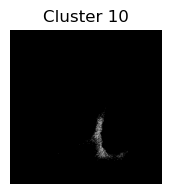

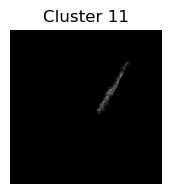

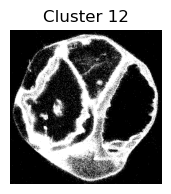

In [60]:
for c in np.unique(labels):

    mask = (cluster_map == c)

    plt.figure(figsize=(2,2))
    plt.imshow(mask, cmap='gray')
    plt.title(f'Cluster {c+1}')
    plt.axis('off')
    plt.show()

Importantly, cluster 5 has pulled out the enriched rim within the mineral of interest!

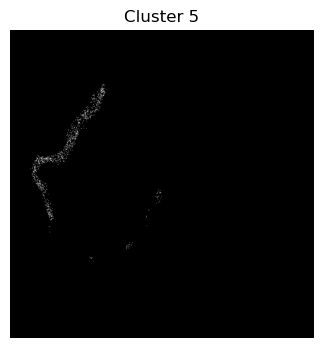

In [59]:
cluster5 = (cluster_map == 4)

plt.figure(figsize=(4,4))
plt.imshow(cluster5, cmap='gray')
plt.title('Cluster 5')
plt.axis('off')
plt.show()

These indepentdent binary masks can then be saved off as .cvs or .msa files containing the pixel/spectral information of each cluster. These files can then be analysed in Bruker to create produce a mineralogical profile. Using these results, stoichemtry calculations can then be used to produce a chemical formula of each mineral cluster. 

Examples of clustering accompanied by calculated mineralogy can be seen in my thesis in both the exposure data set and the minerological data set.